# Approach 1: SBERT feed-forward neural network

This notebook uses a feed-forward neural network to estimate how likely an AI model is to answer a task correctly. It uses the task text and model details, without any test-time labels. The saved training results are shown below. To run a new experiment, set `RUN_NEW_TRAINING = True`.

In [1]:
from pathlib import Path
import os
import sys
import json

os.environ['KERAS_BACKEND'] = 'torch'
candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / 'dl-project']
REPO = next((path for path in candidates if (path / 'dharaneesh/experiments.py').is_file()), None)
if REPO is None:
    raise FileNotFoundError('Open Jupyter from dl-project or dharaneesh.')
sys.path.insert(0, str(REPO))
DATA_DIR = Path(os.environ.get('AIMS_DATA_DIR', str(REPO.parent)))
ENCODER_DIR = os.environ.get('AIMS_ENCODER_DIR')
print('Python:', sys.executable)
print('Data:', DATA_DIR)

Python: C:\Users\dhara\Downloads\aims\aims\data\measurement-db\.venv-approach1\Scripts\python.exe
Data: C:\Users\dhara\Downloads\aims\aims\data\measurement-db


## Training settings

SBERT turns each task into a numerical vector, which we combine with model details and a few text statistics. The FNN has two hidden layers with 64 and 16 neurons and outputs a probability between 0 and 1. Dropout (0.35) and L2 regularization (0.0001) help reduce overfitting. This run uses Brier loss; set `LOSS = 'bce'` to try binary cross-entropy instead.

In [2]:
RUN_NEW_TRAINING = False
RUN_NAME = 'my_fnn_brier_01'
LOSS = 'brier'
EPOCHS = 20
SEED = 42
REBUILD_ZIP = False

## Train the FNN

Training uses the binary responses from Multi-SWE-Bench, REAL, ResearchCodeBench, and SWE-rebench. We split task prompts 80/20 for training and validation, keeping responses to the same prompt together. Training can run for up to 20 epochs, but early stopping keeps the model with the best validation Brier score.

In [3]:
if RUN_NEW_TRAINING:
    from dharaneesh.experiments import train_fnn_submission
    run_dir = train_fnn_submission(DATA_DIR, RUN_NAME, LOSS, EPOCHS, SEED, ENCODER_DIR)
else:
    run_dir = REPO / 'dharaneesh/results'
    print('Displaying the recorded FNN run; training is not being repeated.')

Displaying the recorded FNN run; training is not being repeated.


In [4]:
import pandas as pd
from IPython.display import Image, display

history = pd.read_csv(run_dir / 'fnn_history.csv')
summary = json.loads((run_dir / 'fnn_summary.json').read_text())
assert summary['config']['method']['estimator'] == 'fnn'
assert summary['config']['adaptation_precision'] is None
for row in history.to_dict('records'):
    print(f"Epoch {int(row['epoch'])}: training Brier={row['brier_score']:.4f}, "
          f"validation Brier={row['val_pair_brier']:.4f}, "
          f"validation accuracy={row['val_accuracy']:.4f}")
display(history)
print('Best epoch:', summary['best_epoch'])

Epoch 1: training Brier=0.1947, validation Brier=0.1774, validation accuracy=0.7058
Epoch 2: training Brier=0.1681, validation Brier=0.1658, validation accuracy=0.7474
Epoch 3: training Brier=0.1572, validation Brier=0.1626, validation accuracy=0.7561
Epoch 4: training Brier=0.1487, validation Brier=0.1609, validation accuracy=0.7613
Epoch 5: training Brier=0.1424, validation Brier=0.1615, validation accuracy=0.7616
Epoch 6: training Brier=0.1373, validation Brier=0.1612, validation accuracy=0.7618
Epoch 7: training Brier=0.1330, validation Brier=0.1616, validation accuracy=0.7597
Epoch 8: training Brier=0.1292, validation Brier=0.1602, validation accuracy=0.7660
Epoch 9: training Brier=0.1269, validation Brier=0.1608, validation accuracy=0.7632
Epoch 10: training Brier=0.1248, validation Brier=0.1613, validation accuracy=0.7623
Epoch 11: training Brier=0.1221, validation Brier=0.1619, validation accuracy=0.7673
Epoch 12: training Brier=0.1200, validation Brier=0.1640, validation accur

,accuracy,brier_score,loss,val_accuracy,val_brier_score,val_loss,val_pair_brier,epoch
0,0.720542,0.194746,0.205912,0.705788,0.177358,0.187004,0.177357,1
1,0.738358,0.168110,0.177314,0.747439,0.165810,0.174724,0.165810,2
2,0.769884,0.157205,0.166078,0.756122,0.162626,0.171471,0.162626,3
3,0.786756,0.148695,0.157631,0.761326,0.160936,0.169938,0.160936,4
4,0.800359,0.142368,0.151532,0.761579,0.161508,0.170830,0.161508,5
5,0.809699,0.137253,0.146747,0.761820,0.161159,0.170797,0.161159,6
6,0.818053,0.132955,0.142758,0.759692,0.161593,0.171522,0.161593,7
7,0.824009,0.129173,0.139272,0.766031,0.160199,0.170416,0.160199,8
8,0.827914,0.126895,0.137227,0.763250,0.160792,0.171267,0.160792,9
9,0.830593,0.124762,0.135341,0.762271,0.161306,0.171981,0.161306,10


Best epoch: 8


## Validation results

A lower Brier score means better probability predictions. Accuracy counts correct predictions using 0.5 as the cutoff. The graphs give each model-benchmark pair equal weight, while the summary accuracy gives each response equal weight. The Brier graph excludes the L2 penalty. These validation results helped us choose the model; they are not a separate test or competition score.

,row_brier,pair_brier,accuracy,row_ece,pairs,rows
0,0.193065,0.160199,0.664344,0.068767,147,26977


Training rows: 109305
Validation rows: 26977


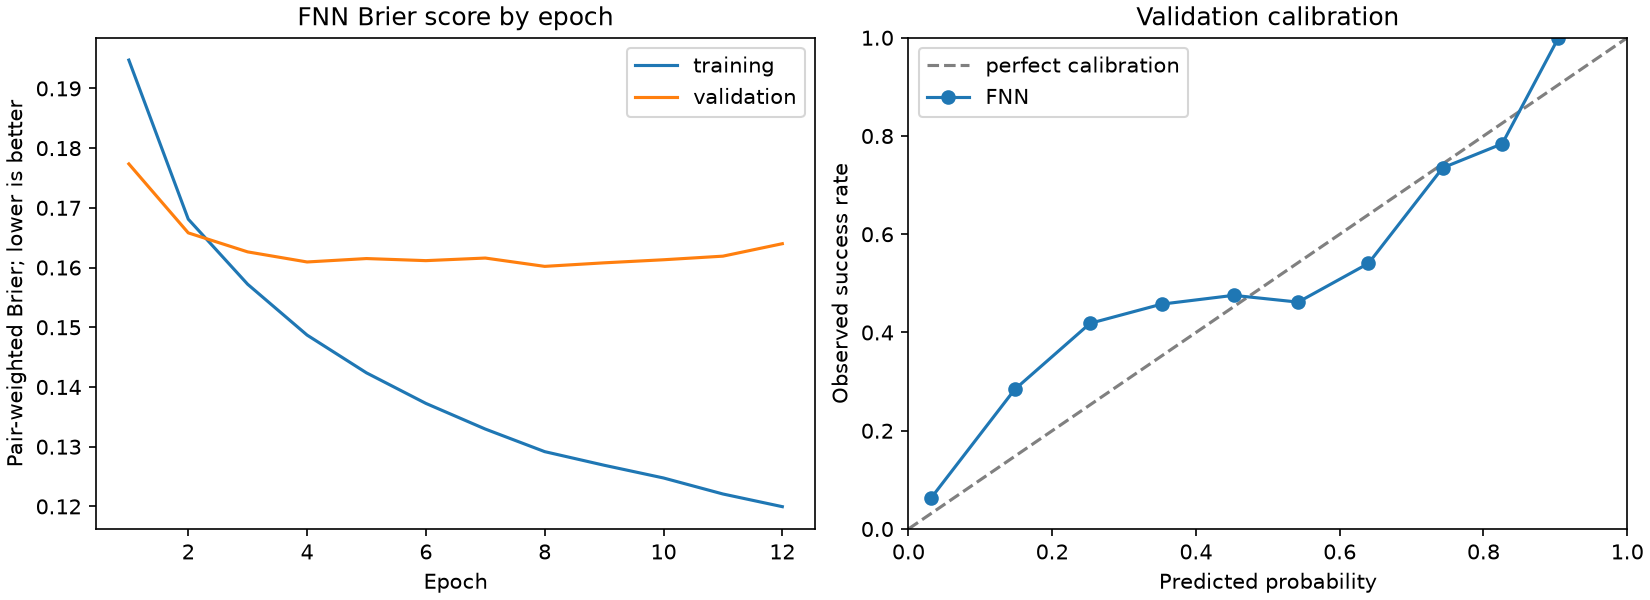

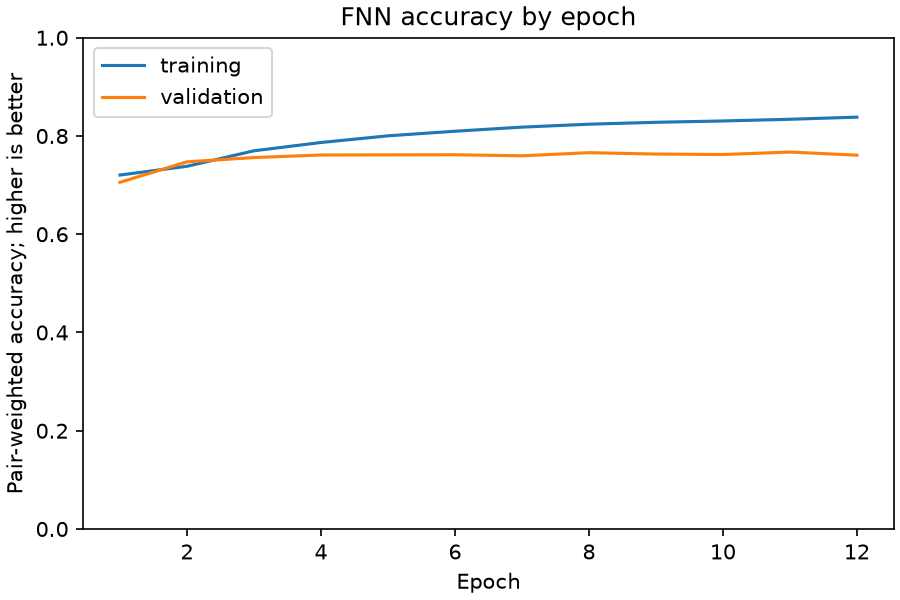

In [5]:
display(pd.DataFrame([summary['validation']]))
print('Training rows:', summary['training_rows'])
print('Validation rows:', summary['validation_rows'])
display(Image(filename=str(run_dir / 'fnn_training.png')))
display(Image(filename=str(run_dir / 'fnn_accuracy.png')))

## FNN submission

Use `submission_fnn.zip` to submit the model on CodaBench. It includes the trained FNN, prediction code, and SBERT text encoder.

In [6]:
from dharaneesh.experiments import package_saved_submission, file_sha256

submission = REPO / 'dharaneesh/submission_fnn.zip'
if REBUILD_ZIP or not submission.is_file():
    submission = package_saved_submission(data_dir=DATA_DIR, encoder_dir=ENCODER_DIR)
print('Upload file:', submission)
print('Size in MB:', round(submission.stat().st_size / 1024**2, 1))
print('SHA-256:', file_sha256(submission))

Upload file: C:\Users\dhara\Downloads\aims\aims\data\measurement-db\dl-project\dharaneesh\submission_fnn.zip
Size in MB: 79.8
SHA-256: d3c0c95605fd855d958d0af2e41aae7d7fd048866a627cbd8069c7e266935730
